# Keystroke dynamics: results

Can we tell who is typing from their typing rhythm alone? This notebook loads every
cleaned session in `data/processed/`, describes the data, and evaluates the three
detectors in `analysis/detector.py`.

**Before running:** bring the data up to date with
`python analysis/run.py` (or `python tools/clean_raw.py data/raw data/processed`).
Then *Run All*. Every number and figure below is computed from the data, so the
notebook stays correct as sessions are added.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

HERE = Path.cwd() if (Path.cwd() / "loading.py").exists() else Path.cwd() / "analysis"
sys.path.insert(0, str(HERE))
from loading import load_all, quality_report
from features import all_features
from similarity import same_vs_different
from evaluation import compare, eer, far_frr, per_user, score_all, window_length_study
from run import DETECTORS, splits_for

warnings.filterwarnings("ignore", category=RuntimeWarning)   # medians of empty windows
pd.set_option("display.precision", 3)

WINDOW = 200        # keystrokes per window

# Chart style: thin marks, hairline grid, recessive axes.
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})
# Categorical colours, in fixed order; each participant keeps its colour in every chart.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

In [2]:
k = load_all(HERE.parent / "data" / "processed")
participants = sorted(k.participant.unique())
COLOR = dict(zip(participants, PALETTE))
sessions = k.groupby("participant").session.unique().map(sorted)
print(f"{len(participants)} participants, {k.groupby(['participant', 'session']).ngroups} sessions, "
      f"{len(k):,} key presses")
print("Sessions:", ", ".join(f"{p} {'/'.join(s)}" for p, s in sessions.items()))

3 participants, 8 sessions, 17,767 key presses
Sessions: P01 S1/S2/S3, P02 S1/S2, P03 S1/S2/S3


## 1. Data quality

One row per session. `hold_missing` is the share of presses with no usable hold time
(release lost, or held outside 10–500 ms); `lost_presses` is the share followed by a
press the collector lost. Sessions recorded with the old Chrome extension lose far
more events than those recorded with the website.

In [3]:
q = quality_report(k)
q.style.format({"hold_missing": "{:.1%}", "lost_presses": "{:.1%}", "minutes": "{:.1f}"}) \
    .background_gradient(subset=["hold_missing", "lost_presses"], cmap=BLUES, vmin=0, vmax=0.4)

## 2. Typing rhythm per participant

Median hold time (how long a key stays down) and median latency (press to next press)
in each session. A usable biometric needs each person to be **consistent across
sessions** and **different from the others**.

hold              latency              
session         S1     S2    S3      S1     S2     S3
participant                                          
P01           92.7   98.7  92.4   192.4  192.7  193.7
P02           97.6  100.0   NaN   149.1  157.4    NaN
P03          101.4  108.4  94.3   218.5  213.3  209.6

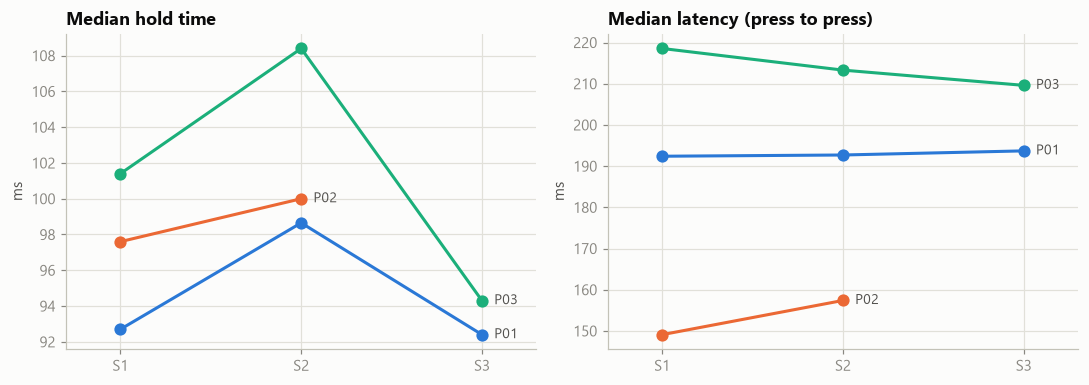

In [4]:
med = k.groupby(["participant", "session"]).agg(hold=("hold", "median"), latency=("latency", "median"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
for ax, col, title in zip(axes, ["hold", "latency"], ["Median hold time", "Median latency (press to press)"]):
    for p in participants:
        s = med.loc[p, col]
        ax.plot(s.index, s.values, marker="o", color=COLOR[p])
        ax.annotate(p, (s.index[-1], s.values[-1]), xytext=(8, 0), textcoords="offset points",
                    va="center", color=INK_2, fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("ms")
    ax.margins(x=0.15)
fig.tight_layout()
med.unstack("session").round(1)

## 3. Letter pairs ("digraphs")

Median latency of the most common letter pairs (␣ is the space bar). Read along a row:
cells in the same participant's columns should look alike, and differ from the other
participants'. The detectors compare windows using exactly these values.

participant    P01                  P02           P03              
session         S1     S2     S3     S1     S2     S1     S2     S3
digraph                                                            
e␣           131.0  127.0  134.0  120.0  131.0  172.0  179.0  164.0
th           116.0  116.0  103.0  125.0  110.0  138.0  139.0  153.0
␣a           120.0  153.0  129.0  146.0  173.0  338.0  310.0  321.0
␣t           185.0  149.0  285.0  174.0  174.0  349.0  270.0  235.0
t␣           171.0  161.0  198.0  119.0  124.0  165.0  172.0  232.0
in           184.0  191.0  195.0  179.0  181.0  196.0  200.0  171.0
s␣           131.0  170.0  155.0  127.0  134.0  199.0  215.0  194.0
d␣           116.0  159.0  129.0  103.0  141.0  196.0  170.0  184.0
␣s           282.0  319.0  230.0  198.0  188.0  486.0  473.0  275.0
he           107.0  133.0  111.0   93.0  111.0  152.0  131.0  140.0
ou           222.0  220.0  224.0  194.0  198.0  238.0  256.0  224.0
n␣           186.0  206.0  190.0  115.0  104.0  234.0  226.0  229.0
a␣           132.0  130.0  116.0  134.0  131.0  173.0  169.0  227.0
y␣           190.0  256.0  222.0  119.0  143.0  180.0  182.0  286.0
␣i           262.0  247.0  294.0  188.0  198.0  512.0  429.0  405.0

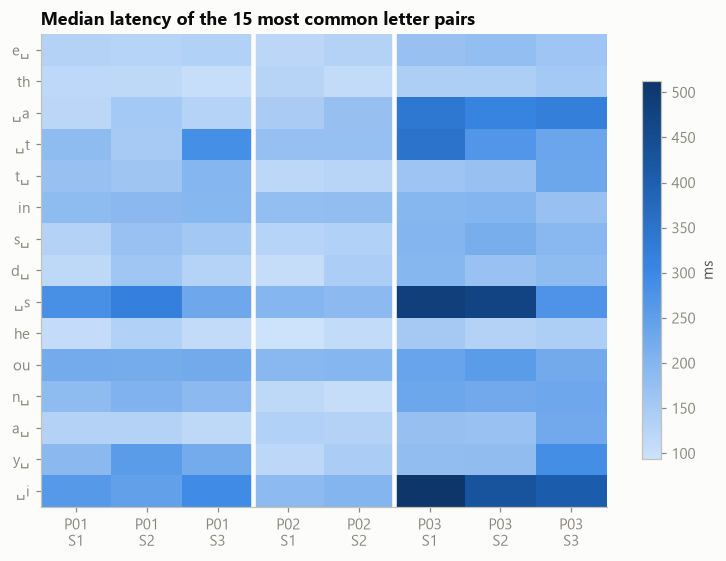

In [5]:
top = k.digraph.value_counts().head(15).index
grid = (k[k.digraph.isin(top)].groupby(["digraph", "participant", "session"]).latency.median()
        .unstack(["participant", "session"]).loc[top])
fig, ax = plt.subplots(figsize=(1.0 + 0.75 * grid.shape[1], 5.2))
im = ax.imshow(grid.values, cmap=BLUES, aspect="auto")
ax.set_xticks(range(grid.shape[1]), [f"{p}\n{s}" for p, s in grid.columns])
ax.set_yticks(range(len(top)), top)
ax.grid(False)
for i in range(grid.shape[1] - 1):
    if grid.columns[i][0] != grid.columns[i + 1][0]:
        ax.axvline(i + 0.5, color="#fcfcfb", linewidth=3)   # gap between participants
ax.set_title("Median latency of the 15 most common letter pairs")
fig.colorbar(im, ax=ax, label="ms", shrink=0.8)
fig.tight_layout()
grid.round(0)

## 4. Same person vs different people

Each session is cut into windows of 200 key presses. For every pair of windows we
compute the distance between their letter-pair timings (`shared_relative`: average
relative difference over the pairs both windows contain). If typing rhythm identifies
people, windows from the **same person** should be closer than windows from **different people**.

,window pairs,median distance
same person,1061,0.266
different people,2092,0.396


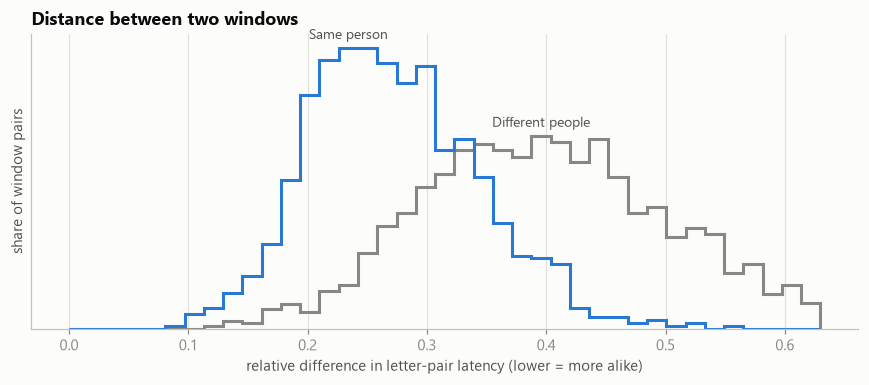

In [6]:
feats = all_features(k, n=WINDOW, min_count=2)
same, diff = same_vs_different(feats)
same, diff = same[np.isfinite(same)], diff[np.isfinite(diff)]
bins = np.linspace(0, np.percentile(np.r_[same, diff], 99), 40)
fig, ax = plt.subplots(figsize=(8, 3.6))
for d, label, color in [(diff, "Different people", MUTED), (same, "Same person", PALETTE[0])]:
    h, _ = np.histogram(d, bins=bins, density=True)
    ax.stairs(h, bins, color=color, linewidth=2)
    peak = bins[np.argmax(h)] + (bins[1] - bins[0]) / 2
    ax.annotate(label, (peak, h.max()), xytext=(0, 6), textcoords="offset points",
                ha="center", color=INK_2, fontsize=9)
ax.set_title("Distance between two windows")
ax.set_xlabel("relative difference in letter-pair latency (lower = more alike)")
ax.set_ylabel("share of window pairs")
ax.set_yticks([])
fig.tight_layout()
pd.DataFrame({"window pairs": [len(same), len(diff)], "median distance": [np.median(same), np.median(diff)]},
             index=["same person", "different people"]).round(3)

## 5. Detectors

Each participant gets a detector trained on their own windows. Every test window is
then scored against every participant's detector: a test against the right person is
*genuine*, against anyone else an *impostor* attempt.

- **EER** (equal error rate): the error when the threshold is set so that false
  accepts and false rejects are equally common. Lower is better.
- **FRR@FAR1%**: how many genuine windows are rejected when at most 1% of impostors may
  get in (a strict, security-style setting).

Splits: **S1+S2 → S3** trains on two sessions and tests on a third day (the realistic
setting, only for participants with three sessions); **S1 → S2** trains on one
session; **within session** trains on the first 60% of each session and tests on the rest.

In [7]:
splits = splits_for(k)
results = compare(feats, DETECTORS, splits)
results.style.format({"EER": "{:.1%}", "FRR@FAR1%": "{:.1%}"}).hide(axis="index")

split,detector,users,EER,FRR@FAR1%,genuine_tests,impostor_tests
S1+S2 -> S3,KNN (k=3),2,25.0%,60.0%,20,20
S1+S2 -> S3,Profile,2,30.0%,75.0%,20,20
S1+S2 -> S3,Outlier count,2,15.0%,100.0%,20,20
S1 -> S2,KNN (k=3),3,11.8%,85.3%,34,68
S1 -> S2,Profile,3,20.6%,94.1%,34,68
S1 -> S2,Outlier count,3,20.6%,88.2%,34,68
within session,KNN (k=3),3,18.2%,90.9%,33,66
within session,Profile,3,27.3%,90.9%,33,66
within session,Outlier count,3,25.8%,84.8%,33,66


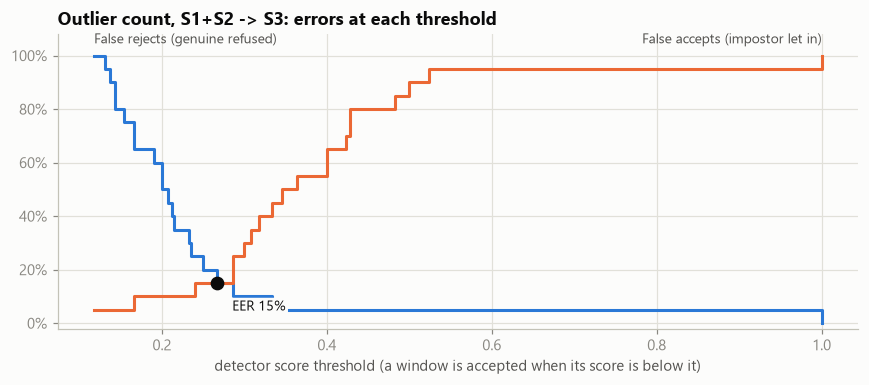

In [8]:
main_split = next(iter(splits))
best = results[results.split == main_split].sort_values("EER").iloc[0]
scores = score_all(feats, DETECTORS[best.detector], **splits[main_split])
curve = far_frr(scores)
curve = curve[np.isfinite(curve.threshold)]
rate, at = eer(far_frr(scores))

fig, ax = plt.subplots(figsize=(8, 3.6))
for col, label, color in [("FRR", "False rejects (genuine refused)", PALETTE[0]),
                          ("FAR", "False accepts (impostor let in)", PALETTE[1])]:
    ax.plot(curve.threshold, curve[col], color=color, drawstyle="steps-post")
    end = curve.iloc[-1] if col == "FAR" else curve.iloc[0]
    ax.annotate(label, (end.threshold, end[col]), xytext=(0, 8), textcoords="offset points",
                ha="right" if col == "FAR" else "left", color=INK_2, fontsize=9)
ax.plot([at], [rate], marker="o", color=INK, markersize=8, zorder=3)
ax.annotate(f"EER {rate:.0%}", (at, rate), xytext=(10, -18), textcoords="offset points", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec="none"))
ax.set_title(f"{best.detector}, {main_split}: errors at each threshold")
ax.set_xlabel("detector score threshold (a window is accepted when its score is below it)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(-0.02, 1.08)
fig.tight_layout()

### EER per participant (same detector and split)

In [9]:
per_user(scores).to_frame().style.format("{:.1%}")

,EER
P01,20.0%
P03,20.0%


## 6. How much typing is needed?

The same detector and split, with windows from 50 to 500 key presses. Longer windows
contain more letter pairs, so they are easier to compare, but each test then needs
more typing and there are fewer tests.

window,EER,FRR@FAR1%,not_comparable,genuine_tests,impostor_tests
50,48.2%,100.0%,0.0%,82,82
100,39.0%,100.0%,0.0%,41,41
200,15.0%,100.0%,0.0%,20,20
300,15.4%,100.0%,0.0%,13,13
500,12.5%,25.0%,0.0%,8,8


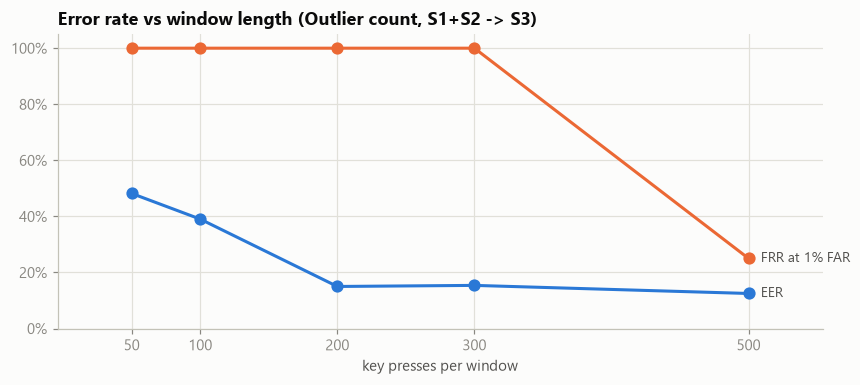

In [10]:
study = window_length_study(k, DETECTORS[best.detector], **splits[main_split])
fig, ax = plt.subplots(figsize=(8, 3.6))
for col, label, color in [("EER", "EER", PALETTE[0]), ("FRR@FAR1%", "FRR at 1% FAR", PALETTE[1])]:
    ax.plot(study.window, study[col], marker="o", color=color)
    ax.annotate(label, (study.window.iloc[-1], study[col].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.set_title(f"Error rate vs window length ({best.detector}, {main_split})")
ax.set_xlabel("key presses per window")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, 1.05)
ax.set_xticks(study.window)
ax.margins(x=0.12)
fig.tight_layout()
study.style.format({"EER": "{:.1%}", "FRR@FAR1%": "{:.1%}", "not_comparable": "{:.1%}"}).hide(axis="index")

## Caveats

- **Few participants and windows.** Each EER above rests on a few dozen genuine tests,
  so one misclassified window moves it by several points. Treat differences between
  detectors of a few points as noise.
- **Data quality differs by collector.** Sessions from the old extension lost up to a
  quarter of their events; a detector may partly learn *how much data is missing*
  rather than how someone types.
- **S1+S2 → S3 needs three sessions.** Participants without an S3 are left out of that
  split entirely.